# Crop Recommendation Model

A machine learning model that recommends the most suitable crop to grow based on soil nutrients and climate conditions.

### 1. Problem Statement
Farmers often choose crops based on experience rather than data. This project builds a classification model that predicts the best crop for a given piece of land using soil and weather measurements.

- **Type of problem:** Multi-class classification
- **Input:** Soil and climate features
- **Output:** Recommended crop name

### 2. Objectives
- Explore and understand the dataset
- Clean and prepare the data for modelling
- Train and compare multiple classification models
- Evaluate the models and select the best one
- Use the final model to make crop predictions

### 3. Dataset Description
- **Source:** "nishchalchandel/crop-recommendation"
- **Rows / columns:** 10 features and 3100 rows
- **Target column:** `crop` (crop name)

| Feature | Description | Unit |
|---|---|---|
| N | Nitrogen content in soil | ratio |
| P | Phosphorus content in soil | ratio |
| K | Potassium content in soil | ratio |
| temperature | Average temperature | °C |
| humidity | Relative humidity | % |
| rainfall | Rainfall | mm |
| ph | Soil pH value | pH scale |
| soil | Soil type | category |
| crop | Recommended crop | category |

---
## Load the Data
Loading the dataset and taking a first look at its structure (shape, column types, first few rows).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Download and load the crop recommendation dataset.
%pip install -q kagglehub

import kagglehub
from pathlib import Path


dataset_path = Path(kagglehub.dataset_download("nishchalchandel/crop-recommendation"))
csv_files = list(dataset_path.rglob("*.csv"))

if not csv_files:
    raise FileNotFoundError("No CSV file was found in the downloaded dataset.")

csv_file = csv_files[0]
df = pd.read_csv(csv_file)
print(f"Loaded {csv_file.name} from {dataset_path}")

100%|██████████| 105k/105k [00:00<00:00, 41.3MB/s]

Extracting files...
Loaded crop_recommendation_dataset.csv from /root/.cache/kagglehub/datasets/nishchalchandel/crop-recommendation/versions/1


In [3]:
# Inspect the dataset shape, column types, rows, and missing values.
print("Shape:", df.shape)

print("\nColumn types:")
print(df.dtypes)

print("\nFirst few rows:")
display(df.head())

print("\nNull values by column:")
print(df.isna().sum())

Shape: (3100, 10)

Column types:
Temperature    float64
Humidity       float64
Rainfall       float64
PH             float64
Nitrogen       float64
Phosphorous    float64
Potassium      float64
Carbon         float64
Soil            object
Crop            object
dtype: object

First few rows:


,Temperature,Humidity,Rainfall,PH,Nitrogen,Phosphorous,Potassium,Carbon,Soil,Crop
0,20.879744,82.002744,202.935536,6.502985,69.30,79.50000,94.4400,0.63,Loamy Soil,rice
1,21.770462,80.319644,226.655537,7.038096,72.02,141.82400,141.6978,1.40,Loamy Soil,rice
2,23.004459,82.320763,263.964248,7.633568,77.77,59.39000,81.8900,1.80,Peaty Soil,rice
3,26.491096,80.283629,242.864034,6.980401,78.65,147.45895,142.9430,1.43,Loamy Soil,rice
4,20.280071,81.604873,262.717340,7.628473,73.98,68.95000,95.7400,1.75,Peaty Soil,rice



Null values by column:
Temperature    0
Humidity       0
Rainfall       0
PH             0
Nitrogen       0
Phosphorous    0
Potassium      0
Carbon         0
Soil           0
Crop           0
dtype: int64


---
## Data Cleaning
Renaming columns, removing unnecessary columns, checking for missing values, duplicates, and handling outliers in the dataset.

In [4]:
# rename the columns to have lowercase names and replace spaces with underscores. use N, P, K, instead of nitrogen, phosphorus, potassium.
df.columns = df.columns.str.lower().str.replace(' ', '_')
df = df.rename(columns={'nitrogen': 'N', 'phosphorous': 'P', 'potassium': 'K'})

In [5]:
# remove the feature carbon since it contains synthetic values and ambiguous unit.
df.drop(columns=['carbon'], inplace=True)

In [6]:
# Separate numerical and categorical features into two DataFrames.
df_num = df.select_dtypes(include="number").copy()
df_cat = df.select_dtypes(exclude="number").copy()

print("Numerical features:", df_num.shape)
print(df_num.dtypes)
print("\nCategorical features:", df_cat.shape)
print(df_cat.dtypes)

Numerical features: (3100, 7)
temperature    float64
humidity       float64
rainfall       float64
ph             float64
N              float64
P              float64
K              float64
dtype: object

Categorical features: (3100, 2)
soil    object
crop    object
dtype: object


In [7]:
# check for duplicate rows in the dataset.
duplicate_rows = df.duplicated()
print(f"Number of duplicate rows: {duplicate_rows.sum()}")

Number of duplicate rows: 0


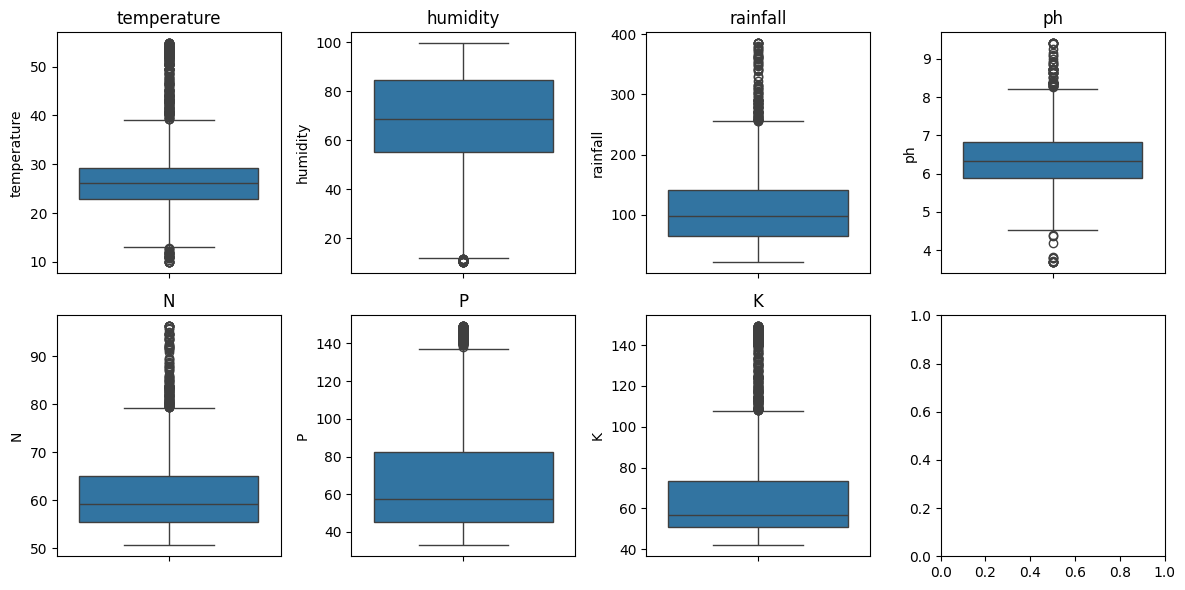

In [8]:
# draw a multiple boxplots, one for each numerical feature.
fig, ax = plt.subplots(2, 4, figsize=(12, 6))

for i, column in enumerate(df_num.columns):
    row = i // 4
    col = i % 4
    sns.boxplot(data=df_num[column], ax=ax[row, col])
    ax[row, col].set_title(column)

plt.tight_layout()
plt.show()

In [9]:
# define a function to remove outliers using the IQR method.
def remove_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]

In [10]:
# define a function to remove outliers using the Percentile method taking 99%ile.
def remove_outliers_percentile(df, column):
    lower_bound = df[column].quantile(0.005)
    upper_bound = df[column].quantile(0.995)
    return df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]

In [11]:
# use the remove_outliers_iqr function to remove outliers from each numerical feature in the dataset.
for column in df_num.columns:
    df = remove_outliers_iqr(df, column)

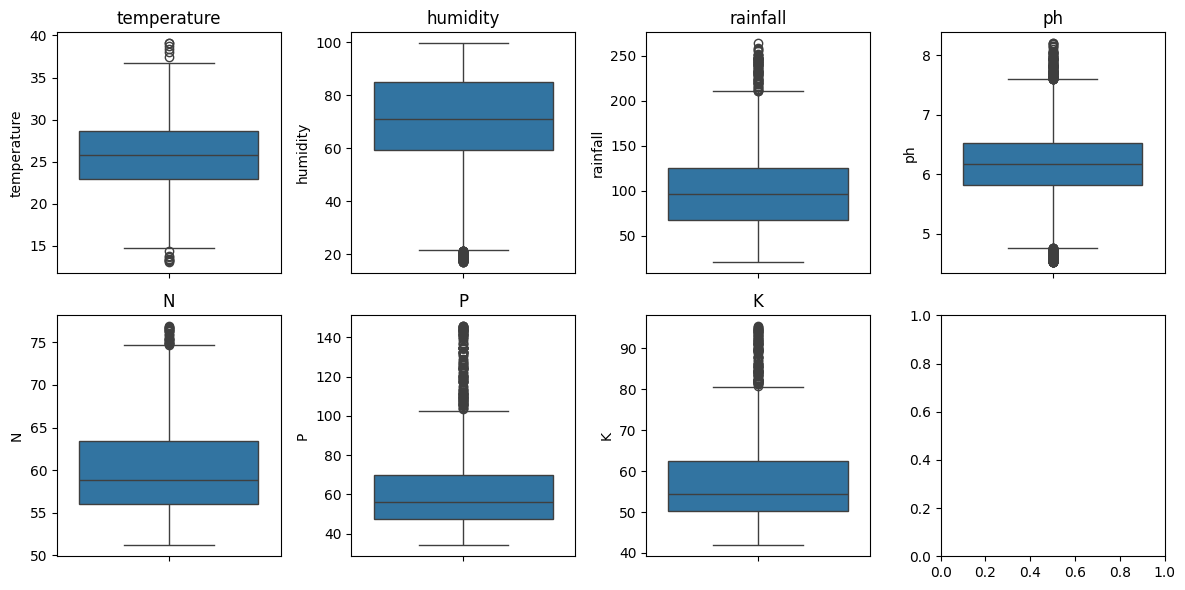

In [12]:
# recheck for outliers after removal by drawing boxplots again.
fig, ax = plt.subplots(2, 4, figsize=(12, 6))

for i, column in enumerate(df_num.columns):
    row = i // 4
    col = i % 4
    sns.boxplot(data=df[column], ax=ax[row, col])
    ax[row, col].set_title(column)

plt.tight_layout()
plt.show()

In [13]:
# display shape of the dataset after outlier removal.
print("Shape after outlier removal:", df.shape)

Shape after outlier removal: (2039, 9)


---
## Exploratory Data Analysis (EDA)
Understanding the data through statistics and plots.

In [14]:
# Display summary statistics for every numerical feature.
df_num = df.select_dtypes(include="number").copy()
display(df_num.describe().T)

,count,mean,std,min,25%,50%,75%,max
temperature,2039.0,25.852649,4.291092,13.058097,22.963084,25.832029,28.705250,39.065555
humidity,2039.0,69.937424,19.462974,16.988612,59.474314,71.189229,84.852153,99.646348
rainfall,2039.0,102.736354,50.137685,20.757078,67.944546,96.326010,125.091092,263.637218
ph,2039.0,6.210213,0.724526,4.523636,5.825383,6.181930,6.535351,8.203607
N,2039.0,60.099367,5.635175,51.180000,55.975000,58.790000,63.445000,76.880000
P,2039.0,61.623971,22.662272,33.989000,47.620000,56.200000,69.885000,145.610000
K,2039.0,57.829956,10.874443,41.860000,50.335000,54.380000,62.470000,95.360000


In [15]:
# Display summary statistics for every categorical feature.
df_cat = df.select_dtypes(exclude="number").copy()

for column in df_cat.columns:
    print(f"\n{column} summary:")
    display(df_cat[column].describe().to_frame())


soil summary:


,soil
count,2039
unique,5
top,Acidic Soil
freq,1246



crop summary:


,crop
count,2039
unique,28
top,Tea
freq,100


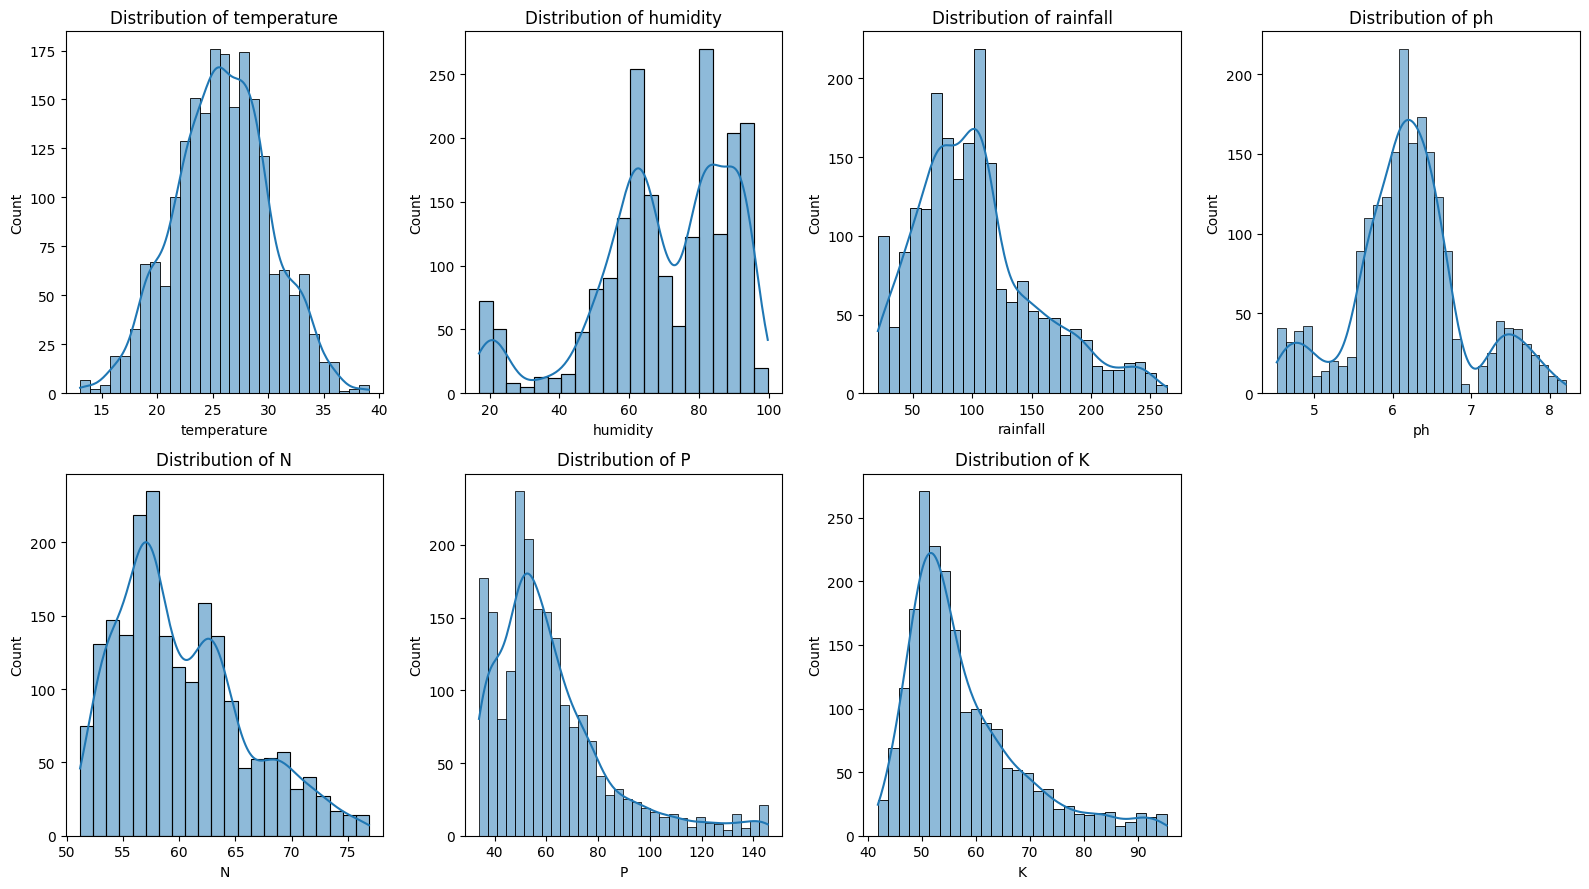

In [16]:
# Plot a histogram with KDE for each numerical feature.
fig, axes = plt.subplots(
    nrows=(len(df_num.columns) + 3) // 4,
    ncols=4,
    figsize=(16, 9),
)
axes = axes.flatten()

for index, column in enumerate(df_num.columns):
    sns.histplot(data=df_num, x=column, kde=True, ax=axes[index])
    axes[index].set_title(f"Distribution of {column}")

for axis in axes[len(df_num.columns):]:
    axis.set_visible(False)

plt.tight_layout()
plt.show()

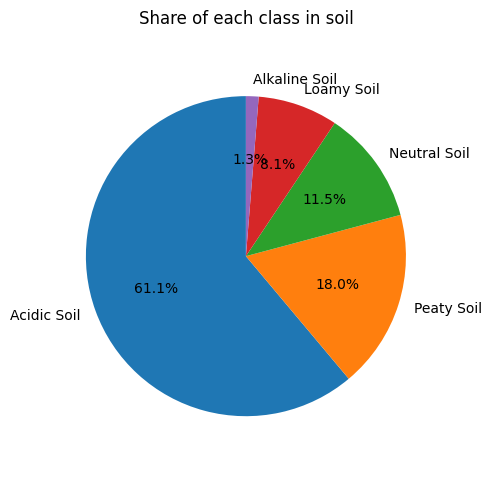

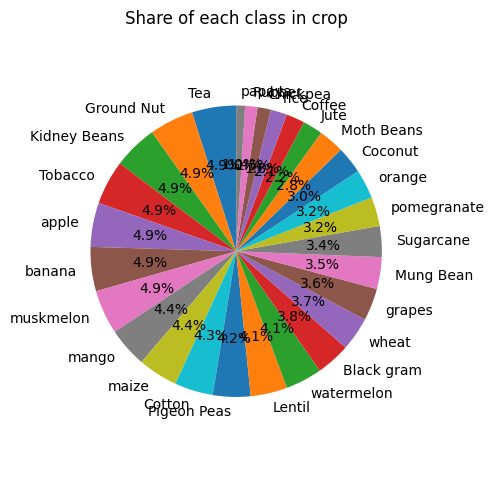

In [17]:
# Plot the class share for every categorical feature as a pie chart.
for column in df_cat.columns:
    class_counts = df_cat[column].value_counts()

    plt.figure(figsize=(5, 5))
    plt.pie(
        class_counts,
        labels=class_counts.index,
        autopct="%1.1f%%",
        startangle=90,
    )
    plt.title(f"Share of each class in {column}")
    plt.axis("equal")
    plt.tight_layout()
    plt.show()

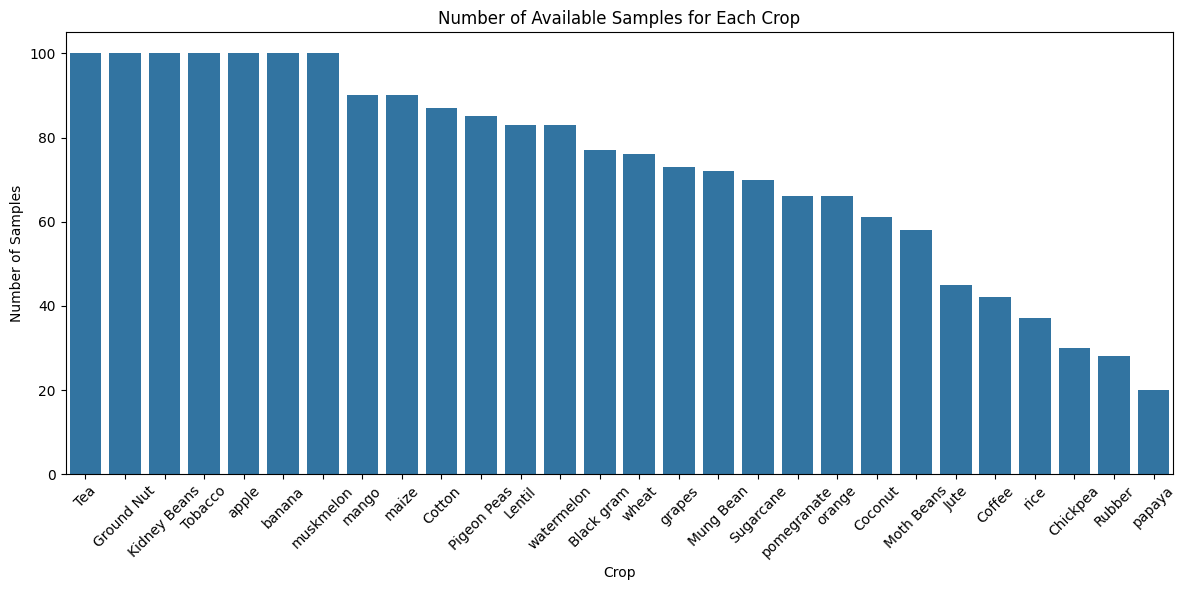

In [18]:
# Plot the number of available samples for each crop.
if "crop" not in df.columns:
    raise KeyError("The dataset must contain a 'crop' column.")

crop_counts = df["crop"].value_counts().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=crop_counts.index, y=crop_counts.values)
plt.title("Number of Available Samples for Each Crop")
plt.xlabel("Crop")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Correlation Analysis
Analyzing the correlation between features and the target variable to identify important predictors.

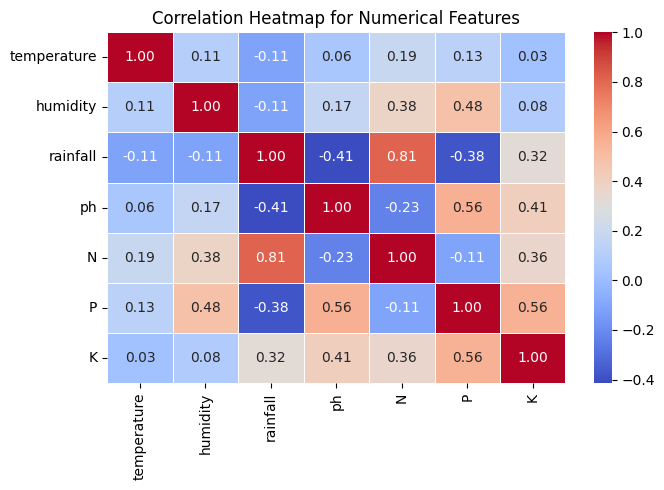

In [20]:
# Plot a heatmap of correlations between numerical features.
correlation_matrix = df_num.corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
)
plt.title("Correlation Heatmap for Numerical Features")
plt.tight_layout()
plt.show()

In [21]:
# Define a function that calculates correlation ratio for a numeric feature and a categorical target.
def correlation_ratio(categories: pd.Series, values: pd.Series) -> float:
    """Return the correlation ratio between categorical and numerical variables."""
    data = pd.DataFrame({"category": categories, "value": values}).dropna()

    category_means = data.groupby("category")["value"].mean()
    category_counts = data.groupby("category")["value"].count()
    overall_mean = data["value"].mean()

    between_group_variance = (
        (category_counts * (category_means - overall_mean) ** 2).sum()
        / len(data)
    )
    total_variance = ((data["value"] - overall_mean) ** 2).sum() / len(data)

    if total_variance == 0:
        return 0.0

    return float((between_group_variance / total_variance) ** 0.5)

In [ ]:
# Calculate correlation ratio between every numerical feature and crop.
correlation_ratios = {
    column: correlation_ratio(df["crop"], df[column])
    for column in df_num.columns
}

correlation_ratio_series = pd.Series(correlation_ratios).sort_values(ascending=False)
print("Correlation ratio with crop:")
print(correlation_ratio_series)

Correlation ratio with crop:
humidity       0.979914
rainfall       0.943827
N              0.936333
ph             0.763793
temperature    0.737117
P              0.732374
K              0.646490
dtype: float64


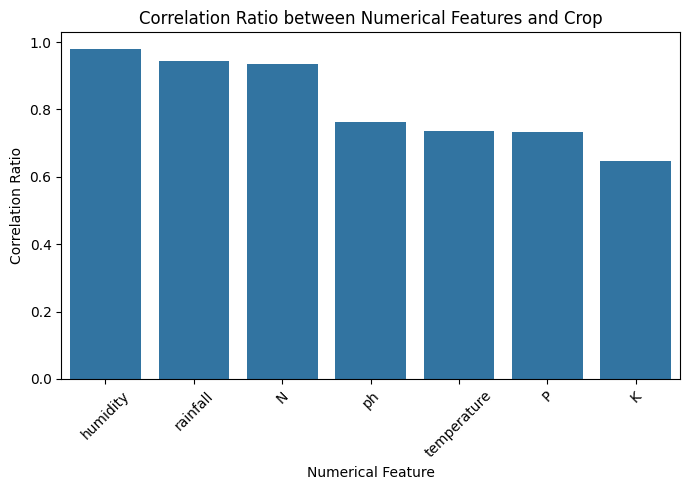

In [28]:
# create a bar plot to visualize the correlation ratio between numerical features and crop.
plt.figure(figsize=(7, 5))
sns.barplot(x=correlation_ratio_series.index, y=correlation_ratio_series.values)
plt.title("Correlation Ratio between Numerical Features and Crop")
plt.xlabel("Numerical Feature")
plt.ylabel("Correlation Ratio")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
# Define a function that calculates Cramer's V for two categorical variables.
from scipy.stats import chi2_contingency


def cramers_v(first_variable: pd.Series, second_variable: pd.Series) -> float:
    """Return Cramer's V statistic for an association between two categories."""
    contingency_table = pd.crosstab(first_variable, second_variable)
    chi_squared = chi2_contingency(contingency_table)[0]
    sample_size = contingency_table.values.sum()

    if sample_size == 0:
        return 0.0

    row_count, column_count = contingency_table.shape
    degrees_of_freedom = min(row_count - 1, column_count - 1)

    if degrees_of_freedom == 0:
        return 0.0

    cramer_value = (chi_squared / (sample_size * degrees_of_freedom)) ** 0.5
    return float(min(cramer_value, 1.0))

In [26]:
# Calculate Cramer's V between soil and crop.
soil_crop_cramers_v = cramers_v(df["soil"], df["crop"])
print(f"Cramer's V between soil and crop: {soil_crop_cramers_v:.4f}")

Cramer's V between soil and crop: 0.3696


#### Note:
As per the above analysis, all features are important for predicting the crop type.

---
## Data Preprocessing
Preparing the data for modeling by encoding categorical variables, scaling numerical features, and splitting the dataset into training and testing sets.

In [ ]:
# One-hot encode the soil categorical feature.
df = pd.get_dummies(df, columns=["soil"], dtype=int)
df.head()

,temperature,humidity,rainfall,ph,N,P,K,crop,soil_Acidic Soil,soil_Alkaline Soil,soil_Loamy Soil,soil_Neutral Soil,soil_Peaty Soil
0,20.879744,82.002744,202.935536,6.502985,69.3000,79.50,94.44,rice,0,0,1,0,0
7,20.280071,82.894086,241.974195,5.718627,72.6000,49.41,65.18,rice,0,0,0,0,1
9,23.223974,83.033227,221.209196,6.336254,73.7000,67.53,84.44,rice,0,0,0,0,1
18,21.865252,80.283629,224.555017,5.953933,71.8700,53.00,68.62,rice,0,0,0,0,1
20,21.325042,80.474764,185.497473,6.442475,69.2805,73.30,84.36,rice,1,0,0,0,0


In [31]:
# Label encode the crop target variable.
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y = pd.Series(label_encoder.fit_transform(df["crop"]), name="crop")
print(dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))

{'Black gram': np.int64(0), 'Chickpea': np.int64(1), 'Coconut': np.int64(2), 'Coffee': np.int64(3), 'Cotton': np.int64(4), 'Ground Nut': np.int64(5), 'Jute': np.int64(6), 'Kidney Beans': np.int64(7), 'Lentil': np.int64(8), 'Moth Beans': np.int64(9), 'Mung Bean': np.int64(10), 'Pigeon Peas': np.int64(11), 'Rubber': np.int64(12), 'Sugarcane': np.int64(13), 'Tea': np.int64(14), 'Tobacco': np.int64(15), 'apple': np.int64(16), 'banana': np.int64(17), 'grapes': np.int64(18), 'maize': np.int64(19), 'mango': np.int64(20), 'muskmelon': np.int64(21), 'orange': np.int64(22), 'papaya': np.int64(23), 'pomegranate': np.int64(24), 'rice': np.int64(25), 'watermelon': np.int64(26), 'wheat': np.int64(27)}


In [32]:
# Separate the encoded features and the label-encoded target.
X = df.drop(columns=["crop"])
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (2039, 12)
Target shape: (2039,)


In [33]:
# Scale the numerical features in X and store the result in X_norm.
from sklearn.preprocessing import StandardScaler

numerical_features = [
    column for column in df_num.columns if column in X.columns
]
X_norm = X.copy()
X_norm[numerical_features] = StandardScaler().fit_transform(
    X_norm[numerical_features]
)
X_norm.head()

,temperature,humidity,rainfall,ph,N,P,K,soil_Acidic Soil,soil_Alkaline Soil,soil_Loamy Soil,soil_Neutral Soil,soil_Peaty Soil
0,-1.159175,0.620063,1.998971,0.404187,1.633115,0.788995,3.367439,0,0,1,0,0
7,-1.298957,0.665872,2.777791,-0.678661,2.218866,-0.539088,0.676067,0,0,0,0,1
9,-0.612739,0.673022,2.363530,0.174005,2.414116,0.260675,2.447626,0,0,0,0,1
18,-0.929455,0.531714,2.430279,-0.353808,2.089291,-0.380636,0.992482,0,0,0,0,1
20,-1.055377,0.541537,1.651082,0.320650,1.629654,0.515345,2.440268,1,0,0,0,0


In [34]:
# Split the unscaled features X and target y into training and testing sets.
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

In [ ]:
# Split the normalized features X_norm and target y into training and testing sets.
X_norm_train, X_norm_test, y_train, y_test = train_test_split(
    X_norm,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)


X_train shape: (1631, 12)
X_test shape: (408, 12)
X_norm_train shape: (1631, 12)
X_norm_test shape: (408, 12)


In [36]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("X_norm_train shape:", X_norm_train.shape)
print("X_norm_test shape:", X_norm_test.shape)

X_train shape: (1631, 12)
X_test shape: (408, 12)
X_norm_train shape: (1631, 12)
X_norm_test shape: (408, 12)


---
## Model Building
Training multiple classification models (e.g., Decision Tree, Random Forest, Gradient Boosting) and comparing their performance using metrics like accuracy, precision, recall, and F1-score.

In [37]:
# Import packages required for model building.
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

In [38]:
# Train logistic regression using the normalized training data.
logistic_model = LogisticRegression(max_iter=1000, random_state=42)
logistic_model.fit(X_norm_train, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [39]:
# Train k-nearest neighbours using the normalized training data.
knn_model = KNeighborsClassifier()
knn_model.fit(X_norm_train, y_train)

KNeighborsClassifier()

In [40]:
# Train a support vector machine using the normalized training data.
svc_model = SVC(random_state=42)
svc_model.fit(X_norm_train, y_train)

SVC(random_state=42)

In [41]:
# Train a decision tree using the unscaled training data.
decision_tree_model = DecisionTreeClassifier(random_state=42)
decision_tree_model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [42]:
# Train a random forest using the unscaled training data.
random_forest_model = RandomForestClassifier(random_state=42)
random_forest_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [43]:
# Train XGBoost using the unscaled training data.
xgboost_model = XGBClassifier(
    random_state=42,
    eval_metric="mlogloss",
)
xgboost_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [44]:
# Train LightGBM using the unscaled training data.
lightgbm_model = LGBMClassifier(random_state=42, verbosity=-1)
lightgbm_model.fit(X_train, y_train)

LGBMClassifier(random_state=42, verbosity=-1)

### Model Evaluation
Evaluating the trained models using k-fold cross-validation and test set performance metrics to select the best model.

In [45]:
# Import packages required for model evaluation.
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
evaluation_results = []

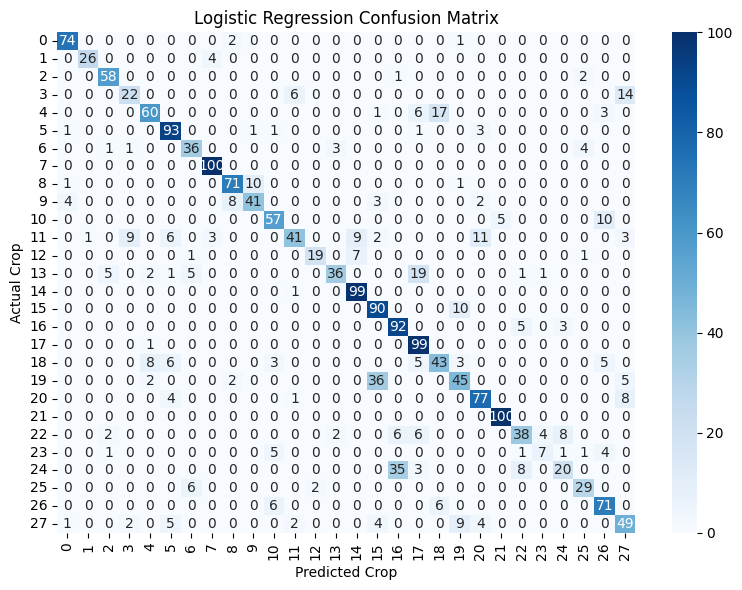

In [47]:
# Evaluate logistic regression with 5-fold cross-validation.
logistic_predictions = cross_val_predict(logistic_model, X_norm, y, cv=cv)
logistic_metrics = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y, logistic_predictions),
    "Precision": precision_score(y, logistic_predictions, average="weighted", zero_division=0),
    "Recall": recall_score(y, logistic_predictions, average="weighted", zero_division=0),
    "F1-score": f1_score(y, logistic_predictions, average="weighted", zero_division=0),
}
evaluation_results.append(logistic_metrics)

plt.figure(figsize=(8, 6))
sns.heatmap(
    confusion_matrix(y, logistic_predictions),
    annot=True,
    fmt="d",
    cmap="Blues",
)
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.tight_layout()
plt.show()

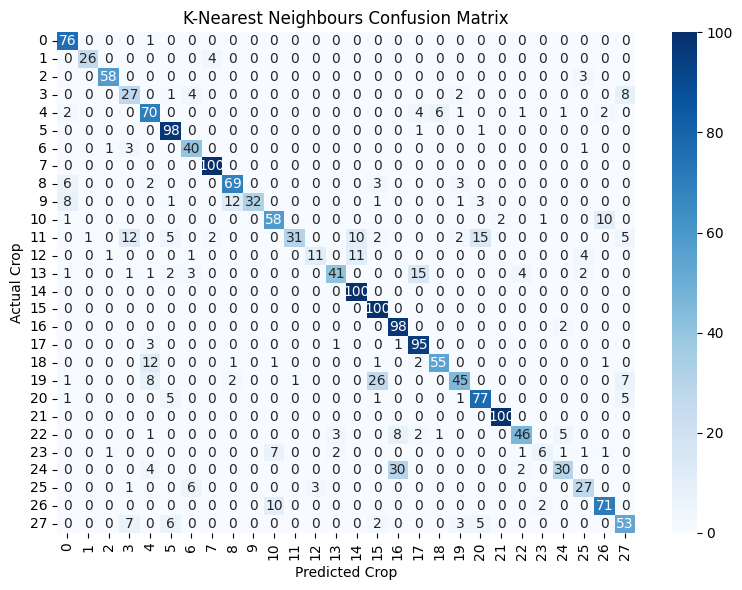

In [49]:
# Evaluate k-nearest neighbours with 5-fold cross-validation.
knn_predictions = cross_val_predict(knn_model, X_norm, y, cv=cv)
knn_metrics = {
    "Model": "K-Nearest Neighbours",
    "Accuracy": accuracy_score(y, knn_predictions),
    "Precision": precision_score(y, knn_predictions, average="weighted", zero_division=0),
    "Recall": recall_score(y, knn_predictions, average="weighted", zero_division=0),
    "F1-score": f1_score(y, knn_predictions, average="weighted", zero_division=0),
}
evaluation_results.append(knn_metrics)

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y, knn_predictions), annot=True, fmt="d", cmap="Blues")
plt.title("K-Nearest Neighbours Confusion Matrix")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.tight_layout()
plt.show()

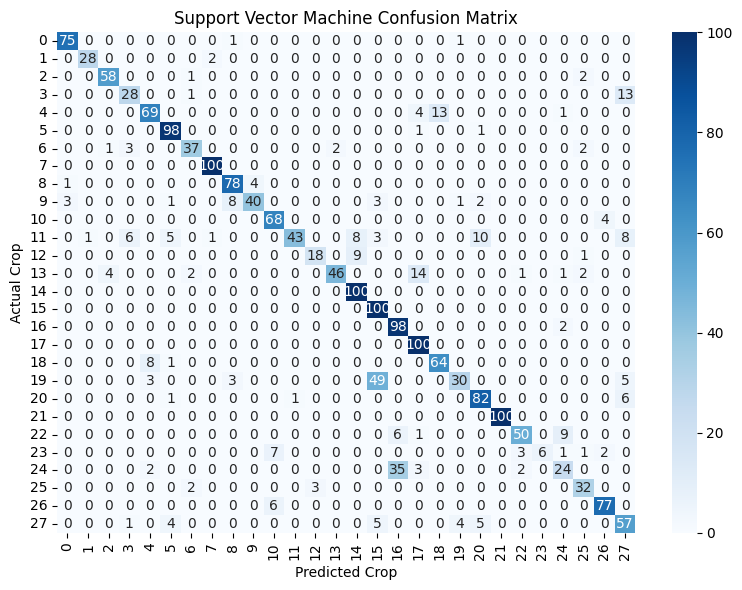

In [50]:
# Evaluate the support vector machine with 5-fold cross-validation.
svc_predictions = cross_val_predict(svc_model, X_norm, y, cv=cv)
svc_metrics = {
    "Model": "Support Vector Machine",
    "Accuracy": accuracy_score(y, svc_predictions),
    "Precision": precision_score(y, svc_predictions, average="weighted", zero_division=0),
    "Recall": recall_score(y, svc_predictions, average="weighted", zero_division=0),
    "F1-score": f1_score(y, svc_predictions, average="weighted", zero_division=0),
}
evaluation_results.append(svc_metrics)

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y, svc_predictions), annot=True, fmt="d", cmap="Blues")
plt.title("Support Vector Machine Confusion Matrix")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.tight_layout()
plt.show()

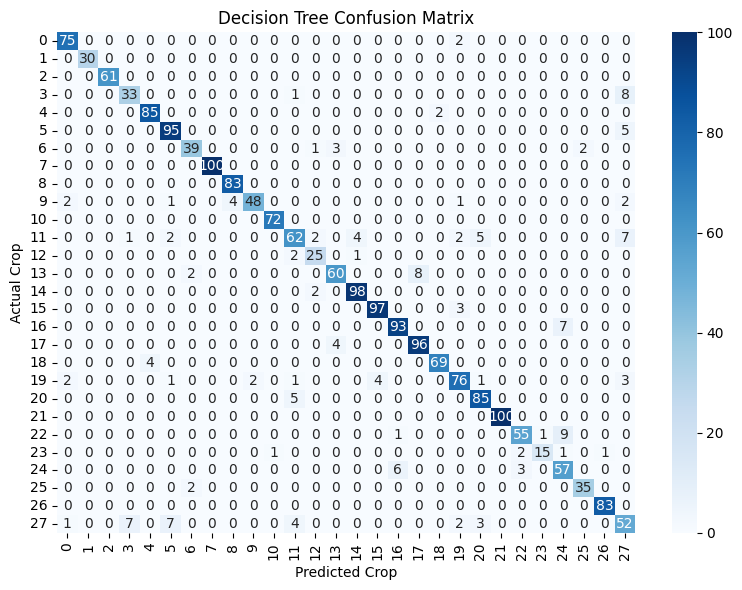

In [51]:
# Evaluate the decision tree with 5-fold cross-validation.
decision_tree_predictions = cross_val_predict(decision_tree_model, X, y, cv=cv)
decision_tree_metrics = {
    "Model": "Decision Tree",
    "Accuracy": accuracy_score(y, decision_tree_predictions),
    "Precision": precision_score(y, decision_tree_predictions, average="weighted", zero_division=0),
    "Recall": recall_score(y, decision_tree_predictions, average="weighted", zero_division=0),
    "F1-score": f1_score(y, decision_tree_predictions, average="weighted", zero_division=0),
}
evaluation_results.append(decision_tree_metrics)

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y, decision_tree_predictions), annot=True, fmt="d", cmap="Blues")
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.tight_layout()
plt.show()

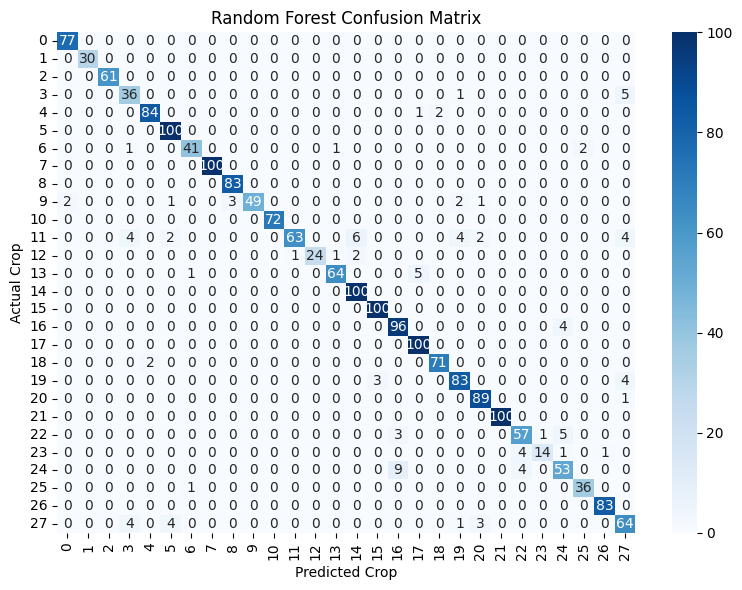

In [52]:
# Evaluate the random forest with 5-fold cross-validation.
random_forest_predictions = cross_val_predict(random_forest_model, X, y, cv=cv)
random_forest_metrics = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y, random_forest_predictions),
    "Precision": precision_score(y, random_forest_predictions, average="weighted", zero_division=0),
    "Recall": recall_score(y, random_forest_predictions, average="weighted", zero_division=0),
    "F1-score": f1_score(y, random_forest_predictions, average="weighted", zero_division=0),
}
evaluation_results.append(random_forest_metrics)

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y, random_forest_predictions), annot=True, fmt="d", cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.tight_layout()
plt.show()

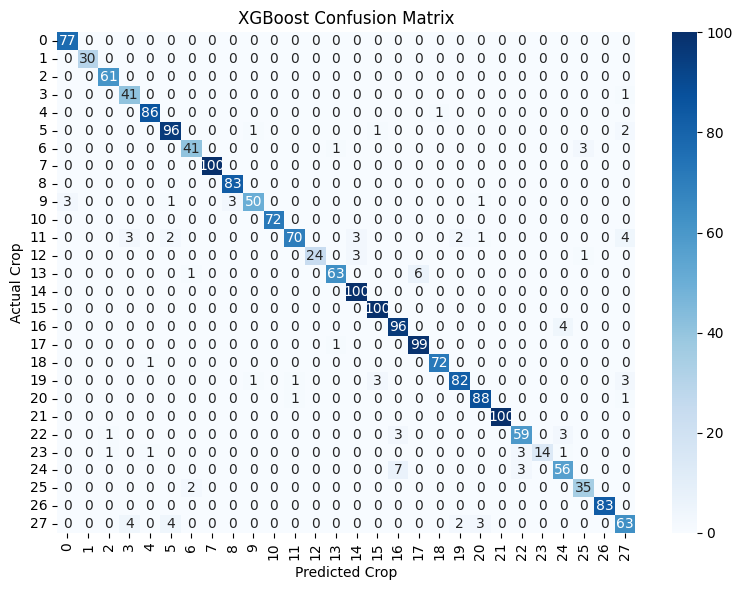

In [53]:
# Evaluate XGBoost with 5-fold cross-validation.
xgboost_predictions = cross_val_predict(xgboost_model, X, y, cv=cv)
xgboost_metrics = {
    "Model": "XGBoost",
    "Accuracy": accuracy_score(y, xgboost_predictions),
    "Precision": precision_score(y, xgboost_predictions, average="weighted", zero_division=0),
    "Recall": recall_score(y, xgboost_predictions, average="weighted", zero_division=0),
    "F1-score": f1_score(y, xgboost_predictions, average="weighted", zero_division=0),
}
evaluation_results.append(xgboost_metrics)

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y, xgboost_predictions), annot=True, fmt="d", cmap="Blues")
plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.tight_layout()
plt.show()

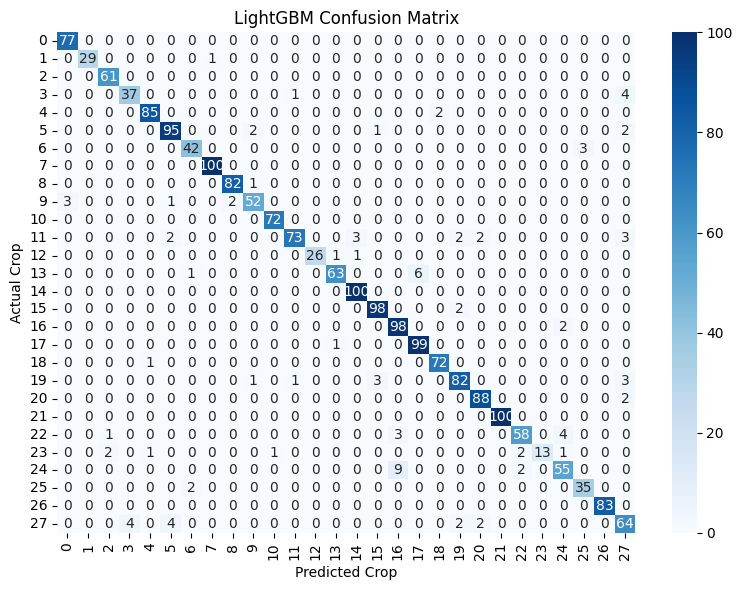

In [54]:
# Evaluate LightGBM with 5-fold cross-validation.
lightgbm_predictions = cross_val_predict(lightgbm_model, X, y, cv=cv)
lightgbm_metrics = {
    "Model": "LightGBM",
    "Accuracy": accuracy_score(y, lightgbm_predictions),
    "Precision": precision_score(y, lightgbm_predictions, average="weighted", zero_division=0),
    "Recall": recall_score(y, lightgbm_predictions, average="weighted", zero_division=0),
    "F1-score": f1_score(y, lightgbm_predictions, average="weighted", zero_division=0),
}
evaluation_results.append(lightgbm_metrics)

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y, lightgbm_predictions), annot=True, fmt="d", cmap="Blues")
plt.title("LightGBM Confusion Matrix")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.tight_layout()
plt.show()

In [55]:
# Show aggregated cross-validation metrics for all models.
evaluation_summary = pd.DataFrame(evaluation_results)
evaluation_summary = evaluation_summary.set_index("Model")
display(evaluation_summary.sort_values(by="Accuracy", ascending=False))

,Accuracy,Precision,Recall,F1-score
Model,,,,
XGBoost,0.951937,0.952650,0.951937,0.951265
LightGBM,0.950956,0.951492,0.950956,0.950363
Random Forest,0.946542,0.947744,0.946542,0.945625
Decision Tree,0.921530,0.921757,0.921530,0.920925
Support Vector Machine,0.836685,0.849275,0.836685,0.825667
K-Nearest Neighbours,0.804316,0.815796,0.804316,0.792756
K-Nearest Neighbours,0.804316,0.815796,0.804316,0.792756
Logistic Regression,0.781265,0.781013,0.781265,0.770674
Logistic Regression,0.781265,0.781013,0.781265,0.770674


---
## Conclusion

#### 1. Best Performing Model

The best-performing model is the one with the highest `Accuracy` in `evaluation_summary`. After running the evaluation cells, identify it with:

#### **XGBoost Classifier**
- **Accuracy:** 0.951937
- **Precision:** 0.952650
- **Recall:** 0.951937
- **F1-Score:** 0.951265

#### **Best  Parameters**
- **n_estimators:** 100
- **max_depth:** 6
- **learning_rate:** 0.3

Use this model as the recommended candidate because it also has the highest cross-validation accuracy among the compared classifiers.

#### 2. Key Findings

- Soil nutrients and climate measurements provide useful patterns for predicting suitable crops.
- Numerical features show measurable differences across crop classes.
- Soil type was converted into numerical indicator features through one-hot encoding.
- Weighted precision, recall, and F1-score show how consistently the classifiers perform across crop classes.
- The 5-fold confusion matrices help identify crop classes that are difficult to distinguish.

#### 3. Model Limitations

- Model performance depends on the quality and representativeness of the available dataset.
- Predictions may not generalize to regions with different soil conditions, climate patterns, or farming practices.
- Cropping suitability also depends on factors outside this dataset, such as season, irrigation, market demand, and pests.
- Cross-validation is not a substitute for validation on data collected from new fields or farms.
- Recommendations should support, rather than replace, local agricultural expertise.

In [ ]:
# Save the best-performing model (XGBoost) to a file using pickle.
import pickle

with open('Crop_Recommendation_Model.pkl', 'wb') as f:
    pickle.dump(xgboost_model, f)

---
## Prediction Pipeline
A pipeline that takes soil and climate measurements as input and outputs the recommended crop using the best-performing model (XGBoost).